<a href="https://colab.research.google.com/github/digshu9242/DAVlab-i1/blob/main/k_means_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (300, 2)


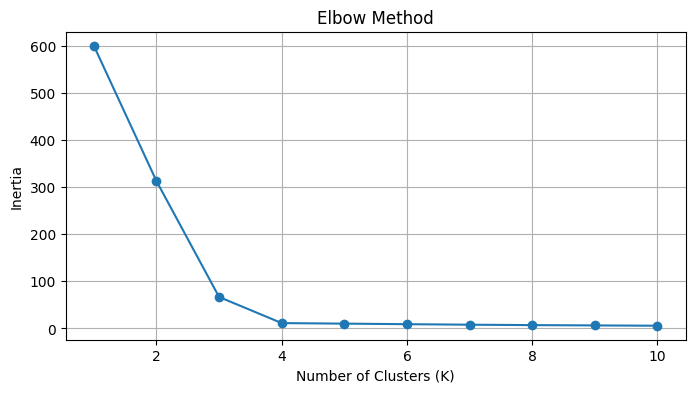

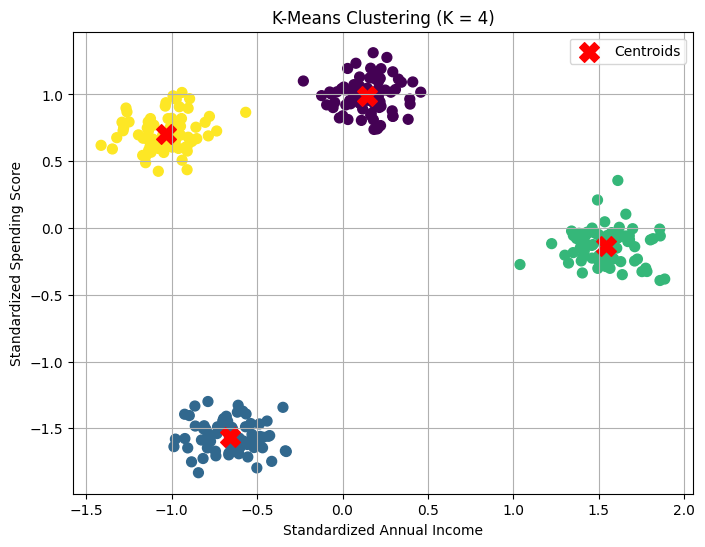


First 10 dataset rows with cluster assignments:
   Annual Income ($k)  Spending Score (1-100)  Cluster
0           -9.205816                6.643647        3
1           -9.526658                7.015878        3
2           -1.851162                8.037611        0
3           -7.053772               -6.001088        1
4          -10.468827                6.517054        3
5           -6.193499               -7.008060        1
6            4.778424                2.281424        2
7           -6.549282               -7.331089        1
8           -2.892537                8.865759        0
9            3.686836                2.498413        2


In [2]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 2: Load the uploaded CSV dataset
df = pd.read_csv('custom_customer_data.csv')

# Extract feature columns (Annual Income & Spending Score)
X = df.iloc[:, :2].values

print("Dataset shape:", X.shape)

# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Step 5: Plot the Elbow graph
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

# Step 6: Apply K-Means with K = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to the DataFrame
df['Cluster'] = clusters

# Step 7: Visualize the clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=clusters, cmap='viridis', s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X', s=200, color='red', label='Centroids'
)

plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("K-Means Clustering (K = 4)")
plt.legend()
plt.grid(True)
plt.show()

# Step 8: Display cluster assignments
print("\nFirst 10 dataset rows with cluster assignments:")
print(df.head(10))